In [56]:
import numpy as np
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
from numpy.typing import NDArray
FloatArray = NDArray[np.float64]
IntArray = NDArray[np.int64]
import sys
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from source.SBM import SBMModel
from source.PartitionPrior import PartitionPrior
from source.Sampler import BaseSampler, SamplerConfig, GibbsSampler, SplitMergeSampler, ChaperonesSampler

In [57]:
def allocate_block_sizes(n, proportions):
    """
    Convert block proportions into integer block sizes.
    The largest remainder method (Hamilton's method) is used
    to ensure that the block sizes sum exactly to n.
    Parameters
    ----------
    n : int
        Total number of nodes.
    proportions : list[float]
        Relative size of each block. Must sum to 1.
    Returns
    -------
    sizes : ndarray
        Integer number of nodes assigned to each block.
    """
    proportions = np.asarray(proportions, dtype=float)
    if n <= 0 or not isinstance(n, (int, np.integer)):
        raise ValueError("n must be a positive integer.")
    if proportions.ndim != 1 or len(proportions) == 0:
        raise ValueError("proportions must be a non-empty 1D array.")
    if np.any(proportions <= 0):
        raise ValueError("All block proportions must be positive.")
    if not np.isclose(proportions.sum(), 1.0):
        raise ValueError("Block proportions must sum to 1.")
    if n < len(proportions):
        raise ValueError("n must be at least the number of blocks.")
    # Calculate ideal (non-integer) block sizes
    expected_sizes = n * proportions
    # Assign the integer part of each expected size
    sizes = np.floor(expected_sizes).astype(int)
    # Calculate the remaining nodes
    remainder = n - sizes.sum()
    # Calculate fractional remainders
    fractional_parts = expected_sizes - sizes
    # Assign remaining nodes to blocks with largest fractional parts
    order = np.argsort(-fractional_parts)
    sizes[order[:remainder]] += 1
    if np.any(sizes == 0):
        raise ValueError("Some blocks have zero nodes. Increase n or adjust proportions.")
    return sizes


# GENERAL SBM GENERATOR
def generate_sbm(n, proportions, P, seed=None):
    """
    Generate an undirected binary Stochastic Block Model (SBM).
    Parameters
    ----------
    n : int
        Total number of nodes.
    proportions : list[float]
        Relative size of each block. Must sum to 1.
    P : ndarray
        Symmetric matrix of block connection probabilities.
    seed : int or None
        Random seed for reproducibility.
    Returns
    -------
    G : networkx.Graph
        Generated undirected graph.
    Y : ndarray
        Adjacency matrix.
    z_true : ndarray
        True block memberships, encoded from 0 to K-1.
    """
    rng = np.random.default_rng(seed)
    # Convert proportions into integer block sizes
    sizes = allocate_block_sizes(n, proportions)
    K = len(sizes)
    # Validate the block probability matrix
    if P.shape != (K, K):
        raise ValueError("P must be a K x K matrix.")
    if not np.allclose(P, P.T):
        raise ValueError("P must be symmetric.")
    if np.any((P < 0) | (P > 1)):
        raise ValueError("Probabilities must be in [0, 1].")
    # Generate true block memberships
    z_true = np.repeat(np.arange(K), sizes)
    # Initialize the adjacency matrix
    Y = np.zeros((n, n), dtype=np.int64)
    # Generate independent Bernoulli edges
    for i in range(n):
        for j in range(i + 1, n):
            p_ij = P[z_true[i], z_true[j]]
            Y[i, j] = rng.binomial(1, p_ij)
            Y[j, i] = Y[i, j]
    # Construct the undirected graph
    G = nx.from_numpy_array(Y)
    # Store true block memberships as node attributes
    nx.set_node_attributes(G,{i: int(z_true[i]) for i in range(n)},"block")
    return G, Y, z_true

In [58]:
# COMMON BLOCK PROPORTIONS
block_proportions = [0.30, 0.30, 0.05, 0.15, 0.20]
# SCENARIO 1
def scenario_1(n=100, seed=123):
    """
    Five communities with unequal relative sizes.
    Strong within-block connectivity and moderate
    between-block connectivity.
    """
    P = np.full((5, 5), 0.25)
    np.fill_diagonal(P, 0.75)
    return generate_sbm(n, block_proportions, P, seed)
# SCENARIO 2
def scenario_2(n=100, seed=456):
    """
    Five blocks with a non-uniform interaction structure.
    Strong connections within blocks and between selected
    pairs of blocks.
    """
    P = np.full((5, 5), 0.25)
    np.fill_diagonal(P, 0.75)
    # Strong between-block interactions
    P[0, 1] = P[1, 0] = 0.75
    P[2, 3] = P[3, 2] = 0.75
    P[1, 4] = P[4, 1] = 0.75
    P[3, 4] = P[4, 3] = 0.75
    return generate_sbm(n, block_proportions, P, seed)
# SCENARIO 3
def scenario_3(n=100, seed=789):
    """
    Five blocks with a diagonal-like interaction structure.
    Selected pairs of blocks exhibit strong interactions,
    while the remaining pairs have weaker interactions.
    """
    P = np.full((5, 5), 0.25)
    np.fill_diagonal(P, 0.75)
    # Strong between-block interactions
    P[0, 2] = P[2, 0] = 0.75
    P[1, 3] = P[3, 1] = 0.75
    P[2, 3] = P[3, 2] = 0.75
    P[2, 4] = P[4, 2] = 0.75
    P[3, 4] = P[4, 3] = 0.75
    return generate_sbm(n, block_proportions, P, seed)
# SCENARIO 4
def scenario_4(n=100, seed=101):
    """
    Five communities with very strong within-block
    connectivity and very weak between-block connectivity.
    """
    P = np.full((5, 5), 0.10)
    np.fill_diagonal(P, 0.90)
    return generate_sbm(n, block_proportions, P, seed)
# SCENARIO 5
def scenario_5(n=100, seed=202):
    """
    Five blocks with an extreme vertical interaction structure.
    Preserves the interaction pattern of Scenario 2.
    """
    P = np.full((5, 5), 0.10)
    np.fill_diagonal(P, 0.90)
    # Strong between-block interactions
    P[0, 1] = P[1, 0] = 0.90
    P[2, 3] = P[3, 2] = 0.90
    P[1, 4] = P[4, 1] = 0.90
    P[3, 4] = P[4, 3] = 0.90
    return generate_sbm(n, block_proportions, P, seed)
# SCENARIO 6
def scenario_6(n=100, seed=303):
    """
    Five blocks with an extreme diagonal-like interaction structure.
    Preserves the interaction pattern of Scenario 3.
    """
    P = np.full((5, 5), 0.10)
    np.fill_diagonal(P, 0.90)
    # Strong between-block interactions
    P[0, 2] = P[2, 0] = 0.90
    P[1, 3] = P[3, 1] = 0.90
    P[2, 3] = P[3, 2] = 0.90
    P[2, 4] = P[4, 2] = 0.90
    P[3, 4] = P[4, 3] = 0.90
    return generate_sbm(n, block_proportions, P, seed)

In [59]:
# GENERATE ALL SIX NETWORKS
# Total number of nodes 
n = 264
G1, Y1, z1 = scenario_1(n=n)
G2, Y2, z2 = scenario_2(n=n)
G3, Y3, z3 = scenario_3(n=n)
G4, Y4, z4 = scenario_4(n=n)
G5, Y5, z5 = scenario_5(n=n)
G6, Y6, z6 = scenario_6(n=n)
# STORE ALL SCENARIOS
networks = {
    "Scenario 1": (G1, Y1, z1),
    "Scenario 2": (G2, Y2, z2),
    "Scenario 3": (G3, Y3, z3),
    "Scenario 4": (G4, Y4, z4),
    "Scenario 5": (G5, Y5, z5),
    "Scenario 6": (G6, Y6, z6)}
# NETWORK SUMMARY
summary = []
for name, (G, Y, z) in networks.items():
    summary.append({
        "Scenario": name,
        "Nodes": G.number_of_nodes(),
        "Edges": G.number_of_edges(),
        "Blocks": len(np.unique(z)),
        "Density": nx.density(G)
    })
summary_df = pd.DataFrame(summary)
print("\nNETWORK SUMMARY")
print(summary_df.to_string(index=False))
# DISPLAY BLOCK SIZES
print("\nBLOCK SIZE CONFIGURATION")
sizes = allocate_block_sizes(n, block_proportions)
for k, (proportion, size) in enumerate(zip(block_proportions, sizes)):
    print(
        f"Block {k}: "
        f"proportion={proportion:.2f}, "
        f"nodes={size}"
    )
print("\nTotal nodes:", sizes.sum())


NETWORK SUMMARY
  Scenario  Nodes  Edges  Blocks  Density
Scenario 1    264  12833       5 0.369657
Scenario 2    264  19386       5 0.558417
Scenario 3    264  16697       5 0.480960
Scenario 4    264  10282       5 0.296175
Scenario 5    264  20638       5 0.594481
Scenario 6    264  16274       5 0.468775

BLOCK SIZE CONFIGURATION
Block 0: proportion=0.30, nodes=79
Block 1: proportion=0.30, nodes=79
Block 2: proportion=0.05, nodes=13
Block 3: proportion=0.15, nodes=40
Block 4: proportion=0.20, nodes=53

Total nodes: 264


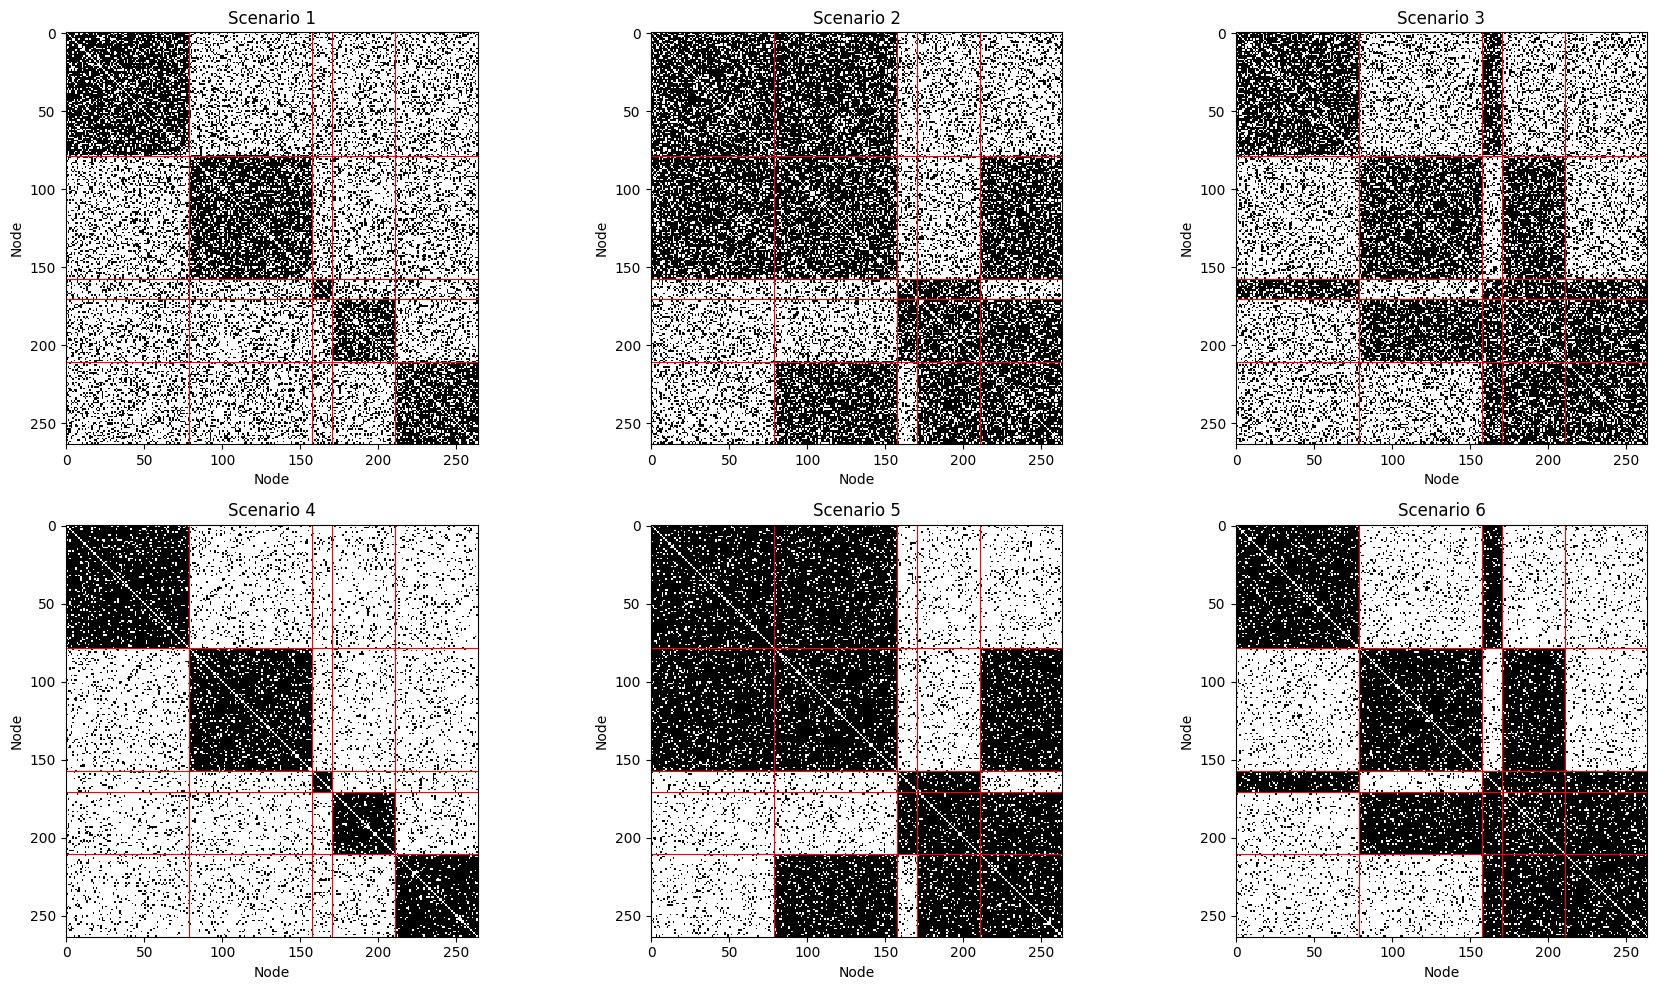

In [60]:

# VISUALIZE THE ADJACENCY MATRICES

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Flatten the axes array
axes = axes.flatten()

for ax, (name, (_, Y, z)) in zip(axes, networks.items()):

    # Plot adjacency matrix
    ax.imshow(
        Y,
        cmap="Greys",
        interpolation="none",
        vmin=0,
        vmax=1
    )

    ax.set_title(name)
    ax.set_xlabel("Node")
    ax.set_ylabel("Node")

    # Add block boundaries
    boundaries = np.where(np.diff(z) != 0)[0] + 0.5

    for boundary in boundaries:
        ax.axhline(boundary, color="red", linewidth=0.8)
        ax.axvline(boundary, color="red", linewidth=0.8)

plt.tight_layout()
plt.show()


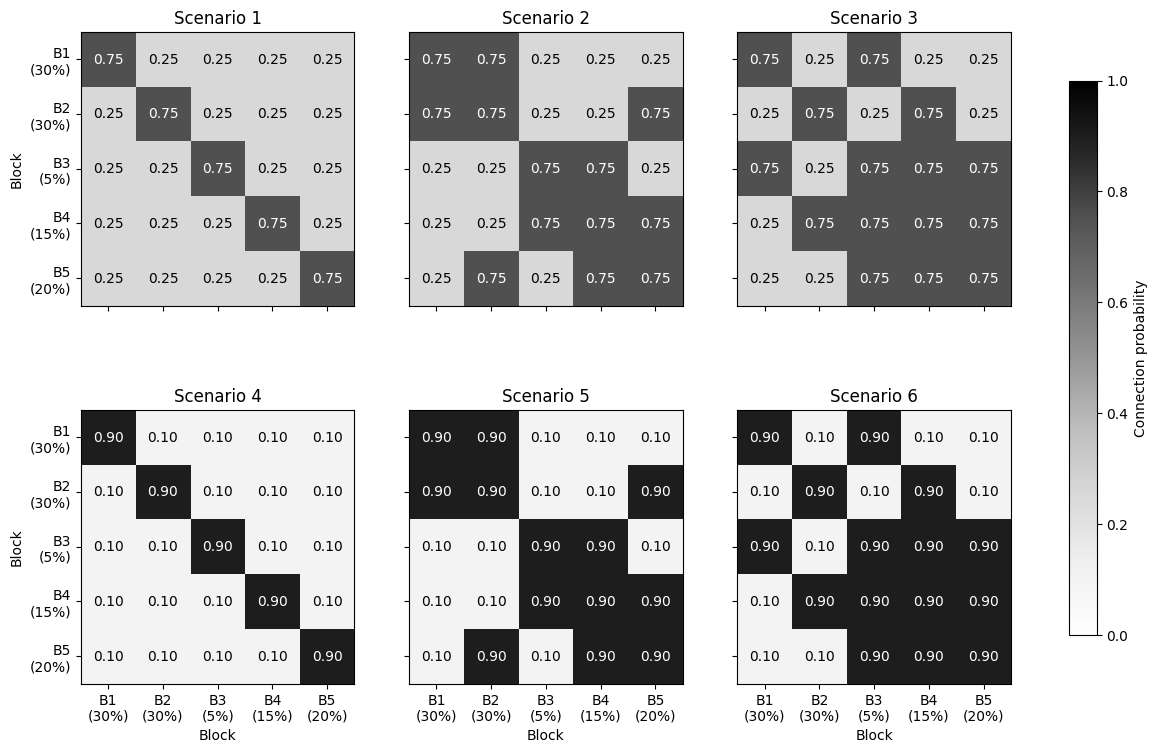

In [61]:

# BLOCK PROBABILITY MATRICES
# Scenario 1: Horizontal organization
P1 = np.full((5, 5), 0.25)
np.fill_diagonal(P1, 0.75)
# Scenario 2: Vertical organization
P2 = np.full((5, 5), 0.25)
np.fill_diagonal(P2, 0.75)
P2[0, 1] = P2[1, 0] = 0.75
P2[2, 3] = P2[3, 2] = 0.75
P2[1, 4] = P2[4, 1] = 0.75
P2[3, 4] = P2[4, 3] = 0.75
# Scenario 3: Diagonal organization
P3 = np.full((5, 5), 0.25)
np.fill_diagonal(P3, 0.75)
P3[0, 2] = P3[2, 0] = 0.75
P3[1, 3] = P3[3, 1] = 0.75
P3[2, 3] = P3[3, 2] = 0.75
P3[2, 4] = P3[4, 2] = 0.75
P3[3, 4] = P3[4, 3] = 0.75
# Scenario 4: Horizontal extreme organization
P4 = np.full((5, 5), 0.10)
np.fill_diagonal(P4, 0.90)
# Scenario 5: Vertical extreme organization
P5 = np.full((5, 5), 0.10)
np.fill_diagonal(P5, 0.90)
P5[0, 1] = P5[1, 0] = 0.90
P5[2, 3] = P5[3, 2] = 0.90
P5[1, 4] = P5[4, 1] = 0.90
P5[3, 4] = P5[4, 3] = 0.90
# Scenario 6: Diagonal extreme organization
P6 = np.full((5, 5), 0.10)
np.fill_diagonal(P6, 0.90)
P6[0, 2] = P6[2, 0] = 0.90
P6[1, 3] = P6[3, 1] = 0.90
P6[2, 3] = P6[3, 2] = 0.90
P6[2, 4] = P6[4, 2] = 0.90
P6[3, 4] = P6[4, 3] = 0.90
# STORE ALL PROBABILITY MATRICES
probability_matrices = [P1, P2, P3, P4, P5, P6]
scenario_names = ["Scenario 1", "Scenario 2", "Scenario 3", "Scenario 4", "Scenario 5", "Scenario 6"]
# VISUALIZE ALL SIX MATRICES
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for ax, P, name in zip(axes, probability_matrices, scenario_names):
    im = ax.imshow(P, cmap="Greys", vmin=0.0, vmax=1.0)
    ax.set_title(name)
    if ax == axes[0] or ax == axes[3]:
        ax.set_ylabel("Block")
        ax.set_yticks(range(5))
        ax.set_yticklabels([f"B{k+1}\n({p:.0%})" for k, p in enumerate(block_proportions)])
    else:
        ax.set_yticks(range(5))
        ax.set_yticklabels([])
    if ax == axes[3] or ax == axes[4] or ax == axes[5]:
        ax.set_xlabel("Block")
        ax.set_xticks(range(5))
        ax.set_xticklabels([f"B{k+1}\n({p:.0%})" for k, p in enumerate(block_proportions)])
    else:
        ax.set_xticks(range(5))
        ax.set_xticklabels([]) 
    # Display probability values inside each cell
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{P[i, j]:.2f}", ha="center", va="center", 
                color="white" if P[i, j] >= 0.75 else "black", fontsize=10)    
# Shared colorbar
fig.colorbar(im,ax=axes.tolist(), label="Connection probability",shrink=0.8)
#plt.tight_layout()
plt.show()


In [62]:
# BUILD PARTITION PRIORS
def build_priors(n):
    """
    Construct the collection of partition priors.
    Parameters
    ----------
    n : int
        Number of nodes in the network.
    Returns
    -------
    priors : dict
        Dictionary containing the five partition priors:
        DM, DP, PY, GN, and MFM.
    """
    priors = {
        "DM": PartitionPrior(kind="DM", beta=3.5 / 50, H_total=50),
        "DP": PartitionPrior(kind="DP", alpha=3.0),
        "PY": PartitionPrior(kind="PY", alpha=-0.3, sigma=0.6),
        "GN": PartitionPrior(kind="GN", gamma=0.45),
        "PCPP": PartitionPrior(kind="PCPP", theta=4.0, omega=0.5)
    }
    # Construct the Mixture of Finite Mixtures (MFM) prior
    from scipy.stats import poisson
    mfm_lambda = 5.0
    k_values = np.arange(1, n + 1)
    p_k = poisson.pmf(k_values, mfm_lambda)
    # Truncate the distribution to K <= n and normalize it
    p_k = p_k / p_k.sum()
    priors["MFM"] = PartitionPrior(kind="MFM", rho=1.0, p_k=tuple(p_k))
    return priors

In [63]:
# VARIATION OF INFORMATION (VI)
from sklearn.metrics import (
    mutual_info_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    adjusted_rand_score,
    fowlkes_mallows_score
)
from scipy.stats import entropy
def variation_of_information(z1, z2):
    """
    Compute the Variation of Information (VI) between
    two partitions.
    VI(z1, z2) = H(z1) + H(z2) - 2 I(z1, z2).
    The partition labels can be arbitrarily permuted.
    Parameters
    ----------
    z1 : array-like
        First partition.
    z2 : array-like
        Second partition.
    Returns
    -------
    float
        Variation of Information between the two partitions.
    """
    z1 = np.asarray(z1)
    z2 = np.asarray(z2)
    h1 = entropy(np.unique(z1, return_counts=True)[1])
    h2 = entropy(np.unique(z2, return_counts=True)[1])
    mutual_information = mutual_info_score(z1, z2)
    return float(h1 + h2 - 2 * mutual_information)


# PARTITION COMPARISON METRICS
def partition_metrics(z1, z2):
    """
    Compute complementary metrics to compare two partitions.
    Metrics:
        VI  : Variation of Information
        NMI : Normalized Mutual Information
        AMI : Adjusted Mutual Information
        ARI : Adjusted Rand Index
        FMI : Fowlkes-Mallows Index
    """
    z1 = np.asarray(z1)
    z2 = np.asarray(z2)
    if z1.ndim != 1 or z2.ndim != 1:
        raise ValueError("Partitions must be one-dimensional.")
    if len(z1) != len(z2):
        raise ValueError("Partitions must have the same length.")
    return {
        "VI": variation_of_information(z1, z2),
        "NMI": normalized_mutual_info_score(z1, z2,average_method="arithmetic"),
        "AMI": adjusted_mutual_info_score(z1, z2, average_method="arithmetic"),
        "ARI": adjusted_rand_score(z1, z2),
        "FMI": fowlkes_mallows_score(z1, z2)
    }


In [64]:

# POSTERIOR PARTITION SUMMARY
def posterior_vi_summary(samples, z_true=None):
    """
    Compute posterior summaries using multiple partition
    comparison metrics.
    The posterior medoid is selected as the partition with
    the smallest average VI distance to all other samples.
    Metrics are evaluated both across posterior samples
    and at the posterior medoid.
    """
    samples = [np.asarray(z) for z in samples]
    n_samples = len(samples)
    if n_samples == 0:
        raise ValueError("No posterior samples available.")
    # Validate posterior samples
    n_nodes = len(samples[0])
    if any(z.ndim != 1 or len(z) != n_nodes for z in samples):
        raise ValueError("All posterior partitions must have the same length.")
    if z_true is not None:
        z_true = np.asarray(z_true)
        if z_true.ndim != 1 or len(z_true) != n_nodes:
            raise ValueError("The true partition must have the same length as the samples.")
    # Number of communities in each posterior sample
    K_samples = np.array([len(np.unique(z)) for z in samples])
    # Compute pairwise VI distance matrix
    D = np.zeros((n_samples, n_samples))
    for i in range(n_samples):
        for j in range(i + 1, n_samples):
            d = variation_of_information(samples[i],samples[j])
            D[i, j] = d
            D[j, i] = d
    # Identify posterior medoid
    medoid_index = np.argmin(D.mean(axis=1))
    z_hat = samples[medoid_index]
    # Posterior radius: 95th percentile of distances to medoid
    distances_to_medoid = D[medoid_index, :]
    vi_radius = np.quantile(distances_to_medoid,0.95)
    # Evaluate all metrics against the true partition
    if z_true is not None:
        sample_metrics = [partition_metrics(z, z_true) for z in samples]
        medoid_metrics = partition_metrics(z_hat,z_true)
        # Average posterior performance
        mean_metrics = {metric: np.mean([result[metric] for result in sample_metrics]) for metric in sample_metrics[0]}
    else:
        mean_metrics = {metric: np.nan for metric in ["VI", "NMI", "AMI", "ARI", "FMI"]}
        medoid_metrics = mean_metrics.copy()
    # Organize results
    summary = {"K_mean": K_samples.mean(),
        "K_median": np.median(K_samples),
        "K_IQR": (np.quantile(K_samples, 0.25),np.quantile(K_samples, 0.75)),
        "VI_radius": vi_radius,
        "z_hat": z_hat}
    # Add posterior mean and medoid metrics
    for metric in mean_metrics:
        summary[f"{metric}_mean_true"] = mean_metrics[metric]
        summary[f"{metric}_hat_true"] = medoid_metrics[metric]
    return summary

In [65]:
# WAIC CALCULATION
from scipy.special import logsumexp
from scipy.stats import beta as beta_dist
def calculate_waic(model, samples, rng=None):
    """
    Compute the pointwise WAIC for an undirected binary SBM.
    The latent partition is integrated over posterior samples,
    and block connection probabilities are sampled from their
    conditional Beta posterior distributions.
    Parameters
    ----------
    model : SBMModel
        Fitted SBM model.
    samples : list
        Posterior samples of partitions.
    rng : int or None
        Random seed for reproducibility.
    Returns
    -------
    float
        WAIC estimate.
    """
    rng = np.random.default_rng(rng)
    Y = model.adjacency
    n = model.n_nodes
    # Extract the upper triangular entries (unique undirected edges)
    rows, cols = np.triu_indices(n, k=1)
    y_obs = Y[rows, cols]
    S = len(samples)
    log_lik = np.zeros((S, len(rows)))
    for s, z in enumerate(samples):
        # Compute block-level sufficient statistics
        stats = model.block_statistics(z)
        z = stats["labels"]
        edges = stats["edges"]
        non_edges = stats["non_edges"]
        K = len(stats["sizes"])
        # Sample block connection probabilities from their conditional Beta posterior
        theta = np.zeros((K, K))
        for h in range(K):
            for k in range(h, K):
                theta_hk = rng.beta(model.a + edges[h, k], model.b + non_edges[h, k])
                theta[h, k] = theta_hk
                theta[k, h] = theta_hk
        # Obtain edge probabilities for observed node pairs
        p = theta[z[rows], z[cols]]
        p = np.clip(p,1e-12,1 - 1e-12)
        # Compute pointwise log-likelihood
        log_lik[s, :] = (y_obs * np.log(p) + (1 - y_obs) * np.log(1 - p))
    # Log pointwise predictive density
    lppd = np.sum(logsumexp(log_lik, axis=0) - np.log(S))
    # Effective number of parameters
    p_waic = np.sum(np.var(log_lik, axis=0, ddof=1))
    # WAIC
    waic = -2 * (lppd - p_waic)
    return float(waic)

In [66]:
# SAMPLER FACTORY
import time
def get_sampler(algorithm, model, prior, config):
    """
    Instantiate the selected sampling algorithm.
    Parameters
    ----------
    algorithm : str
        Name of the sampling algorithm.
    model : SBMModel
        SBM model.
    prior : PartitionPrior
        Partition prior.
    config : SamplerConfig
        Sampling configuration.
    Returns
    -------
    sampler
        Instance of the selected sampler.
    """
    if algorithm == "Gibbs":
        return GibbsSampler(model=model, prior=prior, config=config)
    if algorithm == "Split-Merge":
        return SplitMergeSampler(model=model, prior=prior, config=config)
    if algorithm == "Chaperones":
        return ChaperonesSampler(model=model, prior=prior, config=config)
    raise ValueError(f"Unknown sampling algorithm: {algorithm}")


In [67]:
# LOUVAIN INITIALIZATION OF THE PARTITION
def louvain_initialization(Y, resolution=1.0, seed=123):
    """
    Generate an initial partition using the Louvain algorithm.
    """
    G = nx.from_numpy_array(np.asarray(Y))
    if G.number_of_edges() == 0:
        communities = [{i} for i in range(G.number_of_nodes())]
    else:
        communities = nx.community.louvain_communities(
            G,
            weight="weight",
            resolution=resolution,
            seed=seed
        )
    # Sort communities to obtain reproducible labels
    communities = sorted(communities, key=lambda c: min(c))
    z_initial = np.empty(G.number_of_nodes(), dtype=int)
    for k, community in enumerate(communities):
        for node in community:
            z_initial[node] = k
    return z_initial

In [68]:
# ESS
def effective_sample_size(trace):
    """
    Estimate ESS using the initial positive and monotone
    sequence of autocorrelation pairs (Geyer's approach).
    """
    x = np.asarray(trace, dtype=float).ravel()
    n = len(x)
    if n == 0:
        return np.nan
    if n <= 2 or np.var(x) == 0:
        return float(n)
    # Center the trace
    x = x - np.mean(x)
    # Compute autocovariances using FFT
    fft = np.fft.rfft(x, n=2 * n)
    autocov = np.fft.irfft(fft * np.conjugate(fft))[:n]
    # Normalize autocovariances
    autocov = autocov / n
    if autocov[0] <= 0:
        return float(n)
    rho = autocov / autocov[0]
    # Initial positive and monotone sequence
    pair_sums = []
    previous_pair = np.inf
    for lag in range(1, n - 1, 2):
        pair = rho[lag] + rho[lag + 1]
        if pair <= 0:
            break
        pair = min(pair, previous_pair)
        pair_sums.append(pair)
        previous_pair = pair
    integrated_autocorrelation_time = 1 + 2 * np.sum(pair_sums)
    ess = n / integrated_autocorrelation_time
    return float(np.clip(ess, 1, n))

In [69]:
# RUN A SINGLE INFERENCE EXPERIMENT
def run_algorithm(Y, prior, algorithm, z_true=None, n_iterations=15000, burn_in=5000, thin=10, seed=123, louvain_resolution=1.0):
    """
    Run a sampling algorithm on a single network.
    The function returns posterior partition summaries,
    model selection metrics, and computational time.
    Parameters
    ----------
    Y : ndarray
        Observed adjacency matrix.
    prior : PartitionPrior
        Partition prior.
    algorithm : str
        Sampling algorithm.
    z_true : array-like or None
        True partition, if available.
    n_iterations : int
        Total number of MCMC iterations.
    burn_in : int
        Number of initial iterations to discard.
    thin : int
        Retain one sample every 'thin' iterations.
    seed : int
        Random seed.
    Returns
    -------
    dict
        Dictionary containing inference results and diagnostics.
    """
    # Initialize the SBM model
    model = SBMModel(adjacency=Y, a=1.0,  b=1.0)
    # Define the sampling configuration
    config = SamplerConfig(n_iterations=n_iterations,burn_in=burn_in,thin=thin)
    # Instantiate the selected sampler
    sampler = get_sampler(algorithm=algorithm, model=model, prior=prior, config=config)
    # Run posterior inference and measure execution time
    start = time.perf_counter()
    # Initialize the partition using Louvain
    z_initial = louvain_initialization(Y=Y, resolution=louvain_resolution, seed=seed)
    result = sampler.fit(initial_partition=z_initial, seed=seed)
    elapsed = time.perf_counter() - start
    # Extract posterior partition samples
    samples = [np.asarray(z) for z in result["samples"]]
    # Compute posterior partition summaries
    summary = posterior_vi_summary(samples, z_true=z_true)
    # Compute WAIC
    waic = calculate_waic(model=model, samples=samples, rng=seed)
    # Extract MCMC traces
    log_posterior_trace = np.asarray(result["log_posterior"], dtype=float)
    K_trace = np.asarray(result["n_communities"], dtype=float)
    # Remove burn-in when traces contain all iterations
    if len(log_posterior_trace) == n_iterations:
        log_posterior_trace = log_posterior_trace[burn_in:]
    if len(K_trace) == n_iterations:
        K_trace = K_trace[burn_in:]
    # Calculate effective sample sizes
    ESS_K = effective_sample_size(K_trace)
    ESS_logposterior = effective_sample_size(log_posterior_trace)
    # Calculate ESS per second
    ESS_K_per_second = ESS_K / elapsed
    ESS_logposterior_per_second = ESS_logposterior / elapsed
    return {
        "algorithm": algorithm,
        "prior": prior.kind,

        # Model selection and partition accuracy
        "WAIC": waic,

        # Partition comparison metrics
        "VI_mean_true": summary["VI_mean_true"],
        "VI_hat_true": summary["VI_hat_true"],

        "NMI_mean_true": summary["NMI_mean_true"],
        "NMI_hat_true": summary["NMI_hat_true"],

        "AMI_mean_true": summary["AMI_mean_true"],
        "AMI_hat_true": summary["AMI_hat_true"],

        "ARI_mean_true": summary["ARI_mean_true"],
        "ARI_hat_true": summary["ARI_hat_true"],

        "FMI_mean_true": summary["FMI_mean_true"],
        "FMI_hat_true": summary["FMI_hat_true"],

        # Number of communities
        "K_mean": summary["K_mean"],
        "K_median": summary["K_median"],
        "K_IQR": summary["K_IQR"],

        # Computational performance
        "time_seconds": elapsed,

        # Effective sample sizes
        "ESS_K": ESS_K,
        "ESS_logposterior": ESS_logposterior,
        "ESS_K_per_second": ESS_K_per_second,
        "ESS_logposterior_per_second": ESS_logposterior_per_second,

        # Sampling information
        "n_samples": len(samples),
        "samples": samples,
        "initial_partition": z_initial,
        "log_posterior": result["log_posterior"],
        "n_communities_trace": result["n_communities"]
    }

In [70]:
# BENCHMARK ALL ALGORITHMS AND PRIORS
def benchmark_algorithms(scenarios, priors,algorithms=("Gibbs", "Split-Merge", "Chaperones"),
    n_iterations=15000, burn_in=5000, thin=10,seed=123):
    """
    Benchmark all sampling algorithms across all scenarios
    and partition priors.
    Parameters
    ----------
    scenarios : dict
        Dictionary containing the simulated networks.
    priors : dict
        Dictionary containing the partition priors.
    algorithms : tuple
        Sampling algorithms to evaluate.
    n_iterations : int
        Total number of MCMC iterations.
    burn_in : int
        Number of initial iterations to discard.
    thin : int
        Retain one sample every 'thin' iterations.
    seed : int
        Random seed.
    Returns
    -------
    results_df : pandas.DataFrame
        Complete experimental results.
    tables : dict
        Separate results table for each algorithm.
    """
    results = []
    # Iterate over all simulated network scenarios
    for scenario_name, scenario in scenarios.items():
        Y = np.asarray(scenario["Y"])
        z0 = scenario.get("z0", None)
        # Iterate over all sampling algorithms
        for algorithm in algorithms:
            # Iterate over all partition priors
            for prior_name, prior in priors.items():
                print(f"{scenario_name} | "
                    f"{algorithm} | {prior_name}")
                # Run posterior inference
                output = run_algorithm(Y=Y, prior=prior, algorithm=algorithm,
                    z_true=z0, n_iterations=n_iterations, burn_in=burn_in,
                    thin=thin, seed=seed)
                output["scenario"] = scenario_name
                output["prior"] = prior_name
                results.append(output)
    # Combine all experimental results
    results_df = pd.DataFrame(results)
    # Create a separate results table for each algorithm
    tables = {algorithm: results_df[results_df["algorithm"] == algorithm].copy() for algorithm in algorithms}
    return results_df, tables


In [ ]:
priors = build_priors(n=Y1.shape[0])
scenarios = {
    "Scenario 1": {"Y": Y1, "z0": z1},
    "Scenario 2": {"Y": Y2, "z0": z2},
    "Scenario 3": {"Y": Y3, "z0": z3},
    "Scenario 4": {"Y": Y4, "z0": z4},
    "Scenario 5": {"Y": Y5, "z0": z5},
    "Scenario 6": {"Y": Y6, "z0": z6}
}
results_df, tables = benchmark_algorithms(scenarios=scenarios, priors=priors, algorithms=("Split-Merge",),
    n_iterations=15000, burn_in=5000, thin=10,seed=123)
table_split_merge = tables["Split-Merge"]
display(table_split_merge)


Scenario 1 | Split-Merge | DM


Sampling: 100%|██████████| 15000/15000 [00:58<00:00, 254.27it/s]


Scenario 1 | Split-Merge | DP


Sampling: 100%|██████████| 15000/15000 [00:39<00:00, 375.16it/s]


Scenario 1 | Split-Merge | PY


Sampling: 100%|██████████| 15000/15000 [00:37<00:00, 397.32it/s]
